# Event-locked kernels, M3 part 1: Stage 2 shapes and time constants (LEC vs PFC, >= 5 trials)

Loads and plots only. Numbers come from `run_event_kernels.py`:
- Stage 1 at >= 5 trials, V3 runner, both datasets;
- Stage 2 (`--stage2`), one job per recday and event, merged with `--stage2 --merge`.

Write-up: `code/EVENT_KERNELS.md`, M3 part 1 entry.

- **Stage 2** (`event_kernels.stage2_unit`) is a Poisson GLM whose offset is the training fold's
  full model minus the event block. On top of it sit an exponential ramp exp(-dt/tau) and gamma
  bumps (peak x k in 2/4/8/16). tau and peak are chosen on training sessions; scoring is held out.
- **Classes.** A unit is classed ramp or bump when that shape recovers >= 0.5 of the shape-free
  kernel's held-out deviance gain; `other` when neither does; `none` when the shape-free kernel
  itself gains nothing held out.
- **Reference.** 10 seeded non-locked units per recday and event go through the same path, as the
  null sample.
- **M1 envelope:**
  - tau is recovered within 0.71-1.41x of truth up to 8 min;
  - tau >= 30 min is "slower than the session", not a number;
  - tau is selection-conditioned;
  - kernels are evaluated at the block-mean lag.


In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
FIG = os.path.join(P.REPO, 'data', 'figures', 'event_kernels', 'M3')
fig_path = lambda name: os.path.join(FIG, name)
S1 = {'LEC': P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_lec_kin-strict_mt5_np100')),
      'PFC': P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_pfc_kin-strict_mt5_np100'))}
S2 = {'LEC': P.load_latest(os.path.join(P.STAGE2_DIR, 'stage2_lec_kin-strict_mt5_np100')),
      'PFC': P.load_latest(os.path.join(P.STAGE2_DIR, 'stage2_pfc_kin-strict_mt5_np100'))}
for name, m in [*(('stage1 ' + d, v) for d, v in S1.items()), *(('stage2 ' + d, v) for d, v in S2.items())]:
    print(f"{name}: {os.path.basename(m['_path'])}")

stage1 LEC: stage1_lec_kin-strict_mt5_np100.v1.pkl
stage1 PFC: stage1_pfc_kin-strict_mt5_np100.pkl
stage2 LEC: stage2_lec_kin-strict_mt5_np100.pkl
stage2 PFC: stage2_pfc_kin-strict_mt5_np100.pkl


## Stage 1 at >= 5 trials (V3 runner)

`rank_ok`: no fold's null space reaches held-out rows through a tested column.

In [2]:
P.table_run_summary(S1)

,dataset,anchor,recdays,skipped,units,sessions,rank_ok,r2_cv_median_of_recdays,reset_skipped,n_perm,kin,min_trials
0,LEC,entry,25,0,2851,164,True,0.053819,0,100,strict,5
1,LEC,first_A,25,0,2851,164,True,0.053688,0,100,strict,5
2,PFC,entry,25,1,1229,180,True,0.040478,4,100,strict,5
3,PFC,first_A,25,1,1229,180,True,0.037784,0,100,strict,5


In [3]:
t = P.table_fraction_locked(S1)
t.groupby(['dataset', 'block'])['fraction'].agg(['mean', 'min', 'max', 'count']).round(3).unstack(0)

mean                         min                         max                      count                  
dataset        LEC LEC, 20% rule    PFC    LEC LEC, 20% rule    PFC    LEC LEC, 20% rule    PFC   LEC LEC, 20% rule PFC
block                                                                                                                  
ev_A         0.109         0.109  0.174  0.099         0.097  0.098  0.132         0.135  0.304     5             5   7
ev_A+reward  0.436         0.449  0.502  0.339         0.353  0.214  0.541         0.568  0.742     5             5   7
ev_entry     0.342         0.353  0.322  0.259         0.261  0.160  0.426         0.440  0.533     5             5   7
ev_first_A   0.321         0.333  0.259  0.218         0.220  0.096  0.426         0.437  0.452     5             5   7
ev_reward    0.587         0.604  0.609  0.504         0.527  0.326  0.665         0.698  0.800     5             5   7
kin_fast     0.509         0.527  0.623  0.384         0.404  0.383  0.631         0.651  0.844     5             5   7
kin_slow     0.115         0.120  0.113  0.105         0.108  0.063  0.125         0.135  0.158     5             5   7
place        0.867         0.879  0.742  0.788         0.796  0.481  0.939         0.940  0.912     5             5   7

## Stage 2 runs

In [4]:
pd.concat({ds: m['summary'].groupby('event')[['n_locked', 'n_null']].sum() for ds, m in S2.items()})

n_locked  n_null
    event                   
LEC A            308     250
    entry        972     250
    reward      1656     250
PFC A            194     225
    entry        414     219
    reward       805     203

## F15. Shape classes

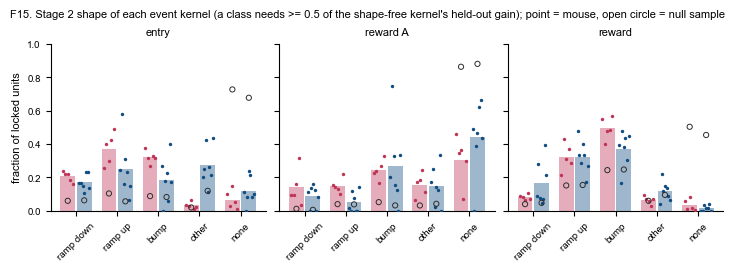

shape                        bump   none  other  ramp_down  ramp_up
dataset event  role                                                
LEC     A      locked       0.246  0.307  0.156      0.140    0.151
               null_sample  0.052  0.864  0.032      0.012    0.040
        entry  locked       0.321  0.068  0.032      0.206    0.373
               null_sample  0.088  0.728  0.020      0.060    0.104
        reward locked       0.496  0.034  0.064      0.083    0.323
               null_sample  0.244  0.504  0.060      0.040    0.152
PFC     A      locked       0.271  0.440  0.149      0.089    0.051
               null_sample  0.032  0.881  0.042      0.006    0.039
        entry  locked       0.187  0.120  0.273      0.170    0.250
               null_sample  0.083  0.678  0.120      0.063    0.057
        reward locked       0.372  0.016  0.118      0.168    0.325
               null_sample  0.248  0.455  0.095      0.048    0.155

In [5]:
P.plot_stage2_classes(S2, out_path=fig_path('F15_stage2_classes')); plt.show()
C = P.table_stage2_classes(S2)
C.pivot_table(index=['dataset', 'event', 'role'], columns='shape', values='fraction', aggfunc='mean').round(3)

## F16. Time constants of ramp units

Per mouse: the median tau and the fraction beyond the session (>= 30 min).

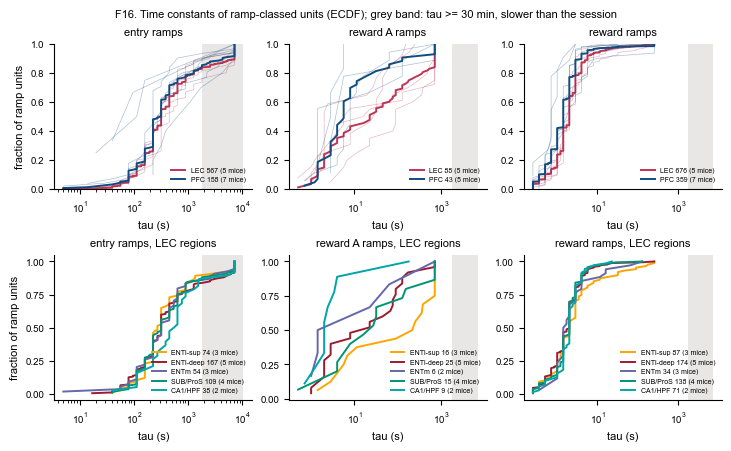

n  median_tau_s  beyond_session  at_grid_edge
dataset event  mouse                                                 
LEC     A      ah08    20        90.510           0.000         0.300
               ah10    20        19.314           0.000         0.150
               ly05    17         2.000           0.000         0.000
               ly06    18         6.828           0.000         0.333
               ly07    13        32.000           0.000         0.077
        entry  ah08   103       273.137           0.155         0.097
               ah10   204       386.274           0.196         0.127
               ly05    69       320.000           0.101         0.072
               ly06    76       452.548           0.276         0.158
               ly07   115       273.137           0.122         0.078
        reward ah08   135         2.000           0.000         0.052
               ah10   239         2.000           0.000         0.063
               ly05    96         2.000           0.000         0.042
               ly06   111         1.414           0.000         0.000
               ly07    95         2.000           0.000         0.000
PFC     A      ab03     6         2.828           0.000         0.000
               ah04    18         8.000           0.000         0.056
               ah07     9         1.414           0.000         0.111
               me08     1         4.000           0.000         0.000
               me11     9         4.000           0.000         0.222
        entry  ab03    34       320.000           0.118         0.088
               ah03     4       136.569           0.250         0.250
               ah04    50       320.000           0.140         0.080
               ah07    31       226.274           0.097         0.065
               me08    10       866.274           0.300         0.200
               me10     3        96.569           0.333         0.333
               me11    26       296.569           0.269         0.077
        reward ab03    89         1.414           0.000         0.011
               ah03     9         0.707           0.000         0.000
               ah04   113         1.414           0.000         0.088
               ah07    71         1.414           0.000         0.042
               me08    18         1.854           0.000         0.056
               me10    11         0.707           0.000         0.182
               me11    48         2.000           0.000         0.146

In [6]:
P.plot_tau_spectrum(S2, out_path=fig_path('F16_tau_spectrum')); plt.show()
tau = P.table_tau(S2)
tau.groupby(['dataset', 'event', 'mouse']).agg(n=('tau_median', 'size'), median_tau_s=('tau_median', 'median'),
    beyond_session=('beyond_session', 'mean'), at_grid_edge=('tau_at_edge', 'mean')).round(3)

In [7]:
tau[tau['dataset'] == 'LEC'].query('~near_boundary').groupby(['event', 'group']).agg(
    n=('tau_median', 'size'), mice=('mouse', 'nunique'), median_tau_s=('tau_median', 'median'),
    beyond_session=('beyond_session', 'mean')).round(3)

n  mice  median_tau_s  beyond_session
event  group                                             
A      CA1/HPF      9     2         2.000           0.000
       ENTl-deep   25     5        22.627           0.000
       ENTl-sup    16     3       237.255           0.000
       ENTm         6     2        12.021           0.000
       SUB/ProS    15     4        27.314           0.000
entry  CA1/HPF     38     2       593.137           0.132
       ENTl-deep  167     5       320.000           0.168
       ENTl-sup    74     3       273.137           0.108
       ENTm        54     3       320.000           0.148
       SUB/ProS   109     4       320.000           0.147
reward CA1/HPF     71     2         2.000           0.000
       ENTl-deep  174     5         2.000           0.000
       ENTl-sup    87     3         2.000           0.000
       ENTm        34     3         1.561           0.000
       SUB/ProS   138     4         2.000           0.000

## F17. Bump peaks

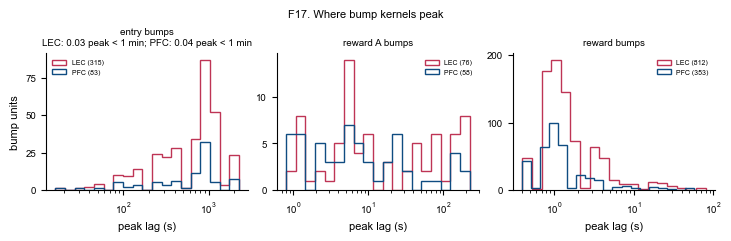

n  median_peak_s  under_1min
dataset event                                 
LEC     A        76         11.314       0.697
        entry   315        905.097       0.025
        reward  812          1.000       0.998
PFC     A        58          5.657       0.862
        entry    83        905.097       0.036
        reward  353          1.000       1.000

In [8]:
P.plot_bump_peaks(S2, out_path=fig_path('F17_bump_peaks')); plt.show()
b = pd.concat([m['table'].assign(dataset=ds) for ds, m in S2.items()])
b = b[(b['role'] == 'locked') & (b['shape'] == 'bump')]
b.groupby(['dataset', 'event']).agg(n=('peak_median', 'size'), median_peak_s=('peak_median', 'median'),
    under_1min=('peak_median', lambda v: float(np.mean(v < 60)))).round(3)

## F18. Example fits

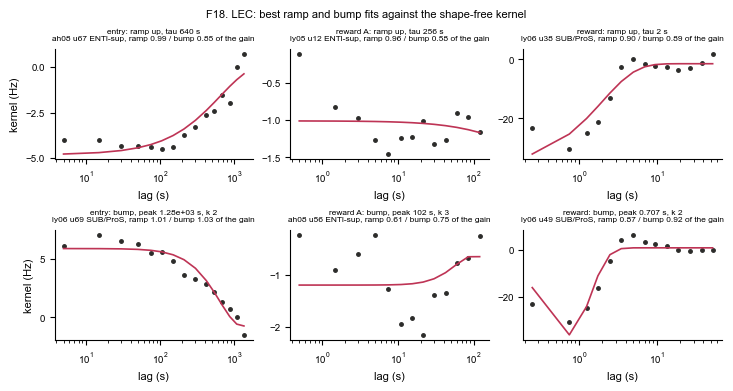

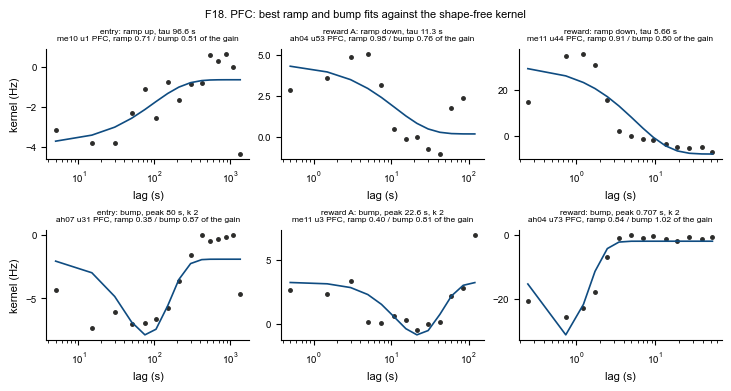

In [9]:
P.plot_stage2_examples(S2, S1, 'LEC', out_path=fig_path('F18_examples_LEC')); plt.show()
P.plot_stage2_examples(S2, S1, 'PFC', out_path=fig_path('F18_examples_PFC')); plt.show()